In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

DATASET_PATH = Path(
    "pubmed_medical_affairs_3layer_corpus_FINAL.csv"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH.resolve()}"
    )

df = pd.read_csv(DATASET_PATH)

required_columns = ["pmid", "title", "abstract", "layer"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df["abstract"] = (
    df["abstract"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df = df[
    (df["abstract"] != "")
    & df["layer"].notna()
].copy()

df.reset_index(drop=True, inplace=True)

print("Dataset loaded successfully.")
print("Records available:", len(df))

print("\nRecords per layer:")
print(df["layer"].value_counts())

display(df[["pmid", "title", "abstract", "layer"]].head(3))

Dataset loaded successfully.
Records available: 21256

Records per layer:
layer
L1_scientific_engagement    9599
L3_comparative_critical     5849
L2_safety_risk              5808
Name: count, dtype: int64


,pmid,title,abstract,layer
0,41483736,Intracranial activity of antibody-drug conjuga...,Antibody-drug conjugates (ADCs) represent a ra...,L1_scientific_engagement
1,41483728,Effect of quetiapine versus haloperidol on del...,INTRODUCTION: Delirium is a neuropsychiatric c...,L1_scientific_engagement
2,41483727,Vision-language models in diagnostic imaging: ...,BACKGROUND: Radiology faces an unprecedented w...,L1_scientific_engagement


In [3]:
# ============================================================
# 3. INITIALISE VADER SENTIMENT ANALYSIS
# ============================================================

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Download the VADER lexicon if it is not already available
nltk.download("vader_lexicon", quiet=True)

sia = SentimentIntensityAnalyzer()

print("VADER sentiment analyser initialised successfully.")

# Test on a sample scientific sentence
sample_text = (
    "The treatment demonstrated improved efficacy, "
    "with no significant increase in adverse events."
)

print("\nSample sentence:")
print(sample_text)

print("\nSentiment scores:")
print(sia.polarity_scores(sample_text))

VADER sentiment analyser initialised successfully.

Sample sentence:
The treatment demonstrated improved efficacy, with no significant increase in adverse events.

Sentiment scores:
{'neg': 0.249, 'neu': 0.37, 'pos': 0.381, 'compound': 0.3612}


In [4]:
# ============================================================
# 4. APPLY VADER TO ALL ABSTRACTS
# ============================================================

from tqdm.auto import tqdm

tqdm.pandas()

# Calculate sentiment scores for each abstract
sentiment_scores = df["abstract"].progress_apply(
    sia.polarity_scores
)

# Convert dictionaries of scores into separate columns
sentiment_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=df.index
)

# Add scores to the dataset
df["sentiment_negative"] = sentiment_df["neg"]
df["sentiment_neutral"] = sentiment_df["neu"]
df["sentiment_positive"] = sentiment_df["pos"]
df["sentiment_compound"] = sentiment_df["compound"]

print("Sentiment analysis completed.")

print("\nDataset shape:", df.shape)

print("\nFirst five records:")
display(
    df[
        [
            "pmid",
            "layer",
            "sentiment_negative",
            "sentiment_neutral",
            "sentiment_positive",
            "sentiment_compound"
        ]
    ].head()
)

print("\nSentiment score summary:")
display(
    df[
        [
            "sentiment_negative",
            "sentiment_neutral",
            "sentiment_positive",
            "sentiment_compound"
        ]
    ].describe().round(4)
)

  0%|          | 0/21256 [00:00<?, ?it/s]

Sentiment analysis completed.

Dataset shape: (21256, 10)

First five records:


,pmid,layer,sentiment_negative,sentiment_neutral,sentiment_positive,sentiment_compound
0,41483736,L1_scientific_engagement,0.111,0.793,0.097,-0.7010
1,41483728,L1_scientific_engagement,0.035,0.913,0.052,0.5574
2,41483727,L1_scientific_engagement,0.075,0.810,0.115,0.8942
3,41483666,L1_scientific_engagement,0.071,0.878,0.051,0.0516
4,41483580,L1_scientific_engagement,0.071,0.834,0.095,0.5267



Sentiment score summary:


,sentiment_negative,sentiment_neutral,sentiment_positive,sentiment_compound
count,21256.0000,21256.0000,21256.0000,21256.0000
mean,0.0592,0.8465,0.0943,0.3716
std,0.0413,0.0559,0.0436,0.7133
min,0.0000,0.5050,0.0000,-0.9997
25%,0.0290,0.8120,0.0630,-0.2500
50%,0.0520,0.8510,0.0900,0.7783
75%,0.0820,0.8860,0.1200,0.9406
max,0.3540,1.0000,0.3850,0.9987


In [5]:
# ============================================================
# 5. CLASSIFY SENTIMENT
# ============================================================

def classify_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["sentiment_category"] = (
    df["sentiment_compound"]
    .apply(classify_sentiment)
)

print("Sentiment categories assigned.")

print("\nOverall sentiment distribution:")
display(
    df["sentiment_category"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Document_Count")
)

print("\nOverall sentiment percentages:")
display(
    (
        df["sentiment_category"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename_axis("Sentiment")
        .reset_index(name="Percentage")
    )
)

Sentiment categories assigned.

Overall sentiment distribution:


,Sentiment,Document_Count
0,Positive,14994
1,Negative,5976
2,Neutral,286



Overall sentiment percentages:


,Sentiment,Percentage
0,Positive,70.54
1,Negative,28.11
2,Neutral,1.35


In [6]:
# ============================================================
# 6. SENTIMENT DISTRIBUTION BY ANALYTICAL LAYER
# ============================================================

sentiment_counts = pd.crosstab(
    df["layer"],
    df["sentiment_category"]
)

# Ensure consistent column order
sentiment_counts = sentiment_counts.reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

sentiment_percentages = (
    pd.crosstab(
        df["layer"],
        df["sentiment_category"],
        normalize="index"
    )
    .reindex(
        columns=["Positive", "Neutral", "Negative"],
        fill_value=0
    )
    .mul(100)
    .round(2)
)

print("Document counts by layer and sentiment:")
display(sentiment_counts)

print("\nSentiment percentages within each layer:")
display(sentiment_percentages)

# Save the summary tables
sentiment_counts.to_csv(
    "sentiment_counts_by_layer.csv"
)

sentiment_percentages.to_csv(
    "sentiment_percentages_by_layer.csv"
)

print("\nSentiment summary tables saved.")

Document counts by layer and sentiment:


sentiment_category,Positive,Neutral,Negative
layer,,,
L1_scientific_engagement,6561,124,2914
L2_safety_risk,4118,87,1603
L3_comparative_critical,4315,75,1459



Sentiment percentages within each layer:


sentiment_category,Positive,Neutral,Negative
layer,,,
L1_scientific_engagement,68.35,1.29,30.36
L2_safety_risk,70.90,1.50,27.60
L3_comparative_critical,73.77,1.28,24.94



Sentiment summary tables saved.


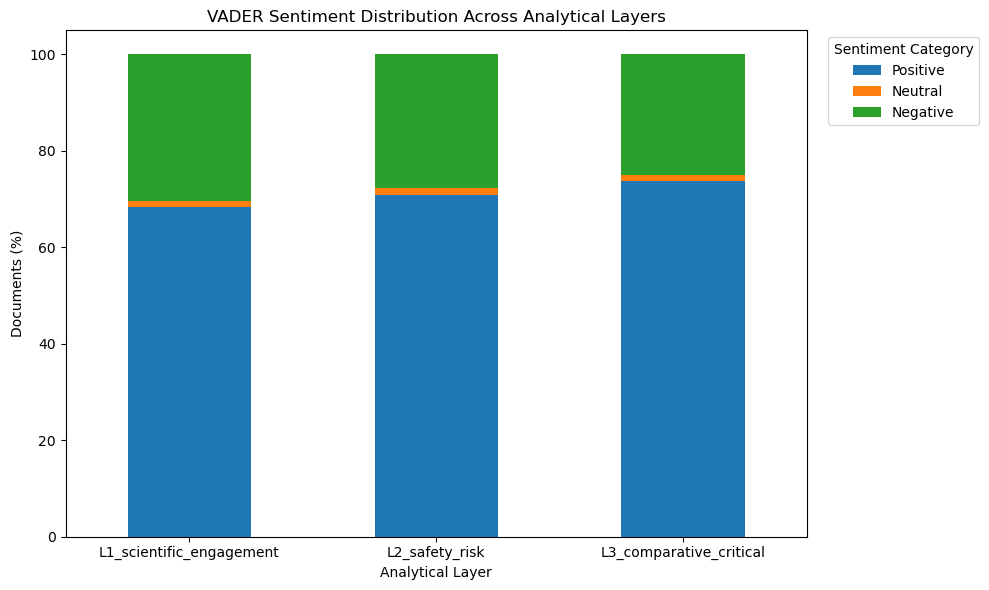

Sentiment visualisation saved.


In [7]:
# ============================================================
# 7. VISUALISE SENTIMENT DISTRIBUTION BY LAYER
# ============================================================

ax = sentiment_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title(
    "VADER Sentiment Distribution Across Analytical Layers"
)

ax.set_xlabel("Analytical Layer")
ax.set_ylabel("Documents (%)")

ax.legend(
    title="Sentiment Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "sentiment_distribution_by_layer.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Sentiment visualisation saved.")

Compound sentiment score statistics:


,Compound_Score
count,21256.0000
mean,0.3716
std,0.7133
min,-0.9997
25%,-0.2500
50%,0.7783
75%,0.9406
max,0.9987


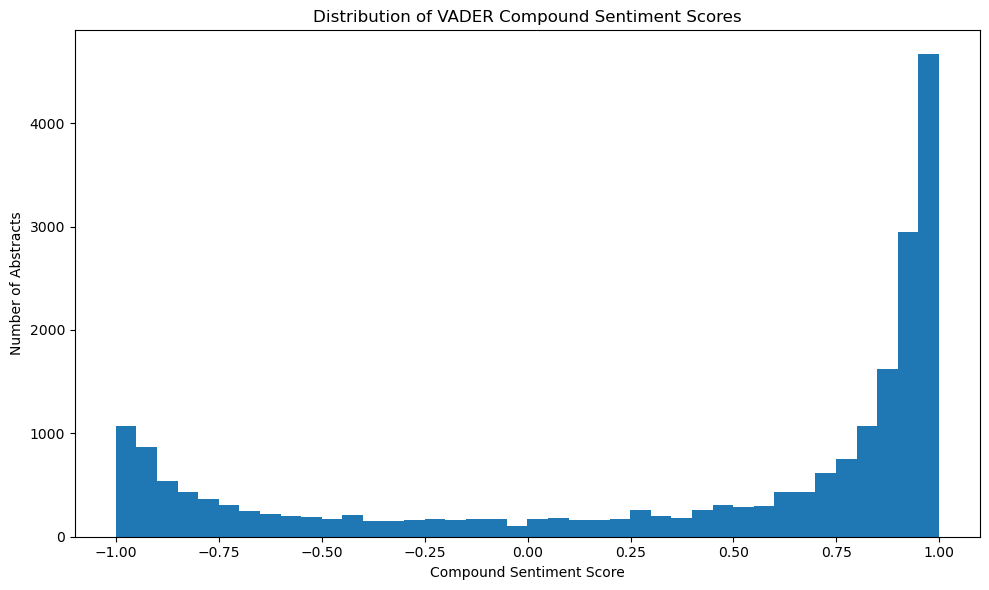

In [8]:
# ============================================================
# 8. EXAMINE THE COMPOUND SENTIMENT DISTRIBUTION
# ============================================================

print("Compound sentiment score statistics:")

display(
    df["sentiment_compound"]
    .describe()
    .round(4)
    .to_frame(name="Compound_Score")
)

# Plot the distribution
plt.figure(figsize=(10, 6))

plt.hist(
    df["sentiment_compound"],
    bins=40
)

plt.title("Distribution of VADER Compound Sentiment Scores")
plt.xlabel("Compound Sentiment Score")
plt.ylabel("Number of Abstracts")

plt.tight_layout()
plt.savefig(
    "vader_compound_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# ============================================================
# 9. INSPECT REPRESENTATIVE SENTIMENT CLASSIFICATIONS
# ============================================================

for category in ["Positive", "Negative", "Neutral"]:

    print("\n" + "=" * 80)
    print(f"EXAMPLES CLASSIFIED AS {category.upper()}")
    print("=" * 80)

    subset = df[
        df["sentiment_category"] == category
    ]

    if subset.empty:
        print("No documents found.")
        continue

    # Select up to three examples near the category's
    # median compound sentiment score
    median_score = subset["sentiment_compound"].median()

    subset = subset.assign(
        distance_from_median=(
            subset["sentiment_compound"] - median_score
        ).abs()
    )

    examples = subset.nsmallest(
        3,
        "distance_from_median"
    )

    for _, row in examples.iterrows():

        print("\nPMID:", row["pmid"])
        print("Layer:", row["layer"])
        print("Sentiment:", row["sentiment_category"])
        print(
            "Compound score:",
            round(row["sentiment_compound"], 4)
        )
        print("Title:", row["title"])
        print("Abstract:", str(row["abstract"])[:800])

        print("-" * 80)


EXAMPLES CLASSIFIED AS POSITIVE

PMID: 41178929
Layer: L1_scientific_engagement
Sentiment: Positive
Compound score: 0.902
Title: Circulating tumor DNA in biliary tract cancers: A review of current applications.
Abstract: Molecular profiling of biliary tract cancers (BTCs) has paved the way for a broader range of therapeutic options, leading to improved survival outcomes. Given the challenges of tissue evaluation in BTCs, circulating tumor DNA (ctDNA) has emerged as a promising non-invasive biomarker for genomic profiling. Bile has been proven to be a reliable ctDNA source, demonstrating higher concordance with tumor tissue than plasma. More importantly, ctDNA provides valuable insights into both clonal evolution and treatment response, including the detection of resistance mechanisms and mutation clearance, which are often associated with disease control. Although its role in recurrence monitoring remains investigational, early studies suggest that ctDNA detection may precede radiolog